# Random submission
## STEP 1 : Install and import libraries

In [111]:
import os
import numpy as np
import pandas as pd
from pathlib import Path
from skimage import io
import matplotlib.pyplot as plt
from PIL import Image

## STEP 2 : Import and parse the data



Path of the data inside the project: /data 

I have the data locally, so I deleted the Colab-specific data acquisition cells.

### Function definition

In [112]:
def show_img(imgs, titles, gray=False, length=None, array_of_array=False):
    """
    Input : - imgs : list of np.arrays of images (or one np.array)
            - titles : list of strings (or one string)

    Description : Plots the images in a row with their corresponding titles.
                  If one image : only plots one image.

    Returns : None
    """
    if not array_of_array:
        if type(imgs) != list:
            imgs = [imgs]
    if type(titles) != list:
        titles = [titles]

    if len(imgs) != len(titles):
        raise ValueError(
            f"""You provided {len(imgs)} images and {len(titles)} titles.
                         Please provide equal number of images and titles."""
        )
    nb_imgs = len(imgs)
    if length:
        plt.figure(figsize=(length, 6))
    else:
        plt.figure()
    for i, (img, title) in enumerate(zip(imgs, titles)):
        plt.subplot(1, nb_imgs, i + 1)
        if gray:
            plt.imshow(img, cmap="gray")
        else:
            plt.imshow(img)
        plt.title(title)
        plt.axis("off")
    plt.show()

In [113]:
# Original sizes we one-hot encode (anything else, including non-square images, is "other")
SIZE_CATEGORIES = ["72", "160", "240", "other"]
MODE_CATEGORIES = ["RGBA", "P", "LA", "RGB", "L"]


def load_data(folder_path: str, target_size=(72, 72)):
    """
    Input : - folder_path : folder containing the PNG images
            - target_size : (width, height) every image is resized to

    Returns : - images : uint8 array (N, H, W, 4) = raw RGB + alpha channel
              - ids    : list of image ids (file names without extension)
              - meta   : float32 array (N, 9) = one-hot original size + one-hot original PNG mode
    """
    path_to_images = Path(folder_path)
    ids, dataset, meta = [], [], []

    for img_file in sorted(path_to_images.iterdir()):
        ids.append("".join(img_file.name.split(".")[:-1]))
        img = Image.open(img_file)

        # 1) File properties. Each vendor exports at its own resolution (facebook 240x240,
        #    whatsapp 160x160, apple/google/samsung 72x72, ...): the resize below erases this,
        #    so we record it before resizing.
        width, height = img.size
        size = str(width) if width == height and str(width) in SIZE_CATEGORIES else "other"
        one_hot = np.zeros(len(SIZE_CATEGORIES) + len(MODE_CATEGORIES), dtype=np.float32)
        one_hot[SIZE_CATEGORIES.index(size)] = 1
        one_hot[len(SIZE_CATEGORIES) + MODE_CATEGORIES.index(img.mode)] = 1
        meta.append(one_hot)

        # 2) Pixels. Every emoji sits on a transparent background. We keep the raw RGB values
        #    (including the colors stored under fully transparent pixels, which differ by vendor)
        #    AND the alpha channel as a 4th channel. RGB and alpha are resized separately on
        #    purpose: resizing an RGBA image directly makes Pillow premultiply by alpha, which
        #    sets every transparent pixel to black and erases that information.
        rgba = img.convert("RGBA")
        rgb = rgba.convert("RGB").resize(target_size)
        alpha = rgba.getchannel("A").resize(target_size)
        dataset.append(np.dstack([np.array(rgb), np.array(alpha)]))

    return np.array(dataset), ids, np.array(meta)

##  STEP 3 : Data Analysis
### Getting the shapes

This cell will return an error at first : it is normal, the preprocessing given as an example is incorrect on the cell above. It is part of the challenge to find the correct pre processing and loading of the data for the model as it has an impact on the performance.

In [114]:
X_train, X_train_ids, meta_train = load_data("data/train")
print("Shape of train dataset", X_train.shape, "| metadata", meta_train.shape)

X_test, X_test_ids, meta_test = load_data("data/test")
print("Shape of test dataset", X_test.shape, "| metadata", meta_test.shape)

y_train = pd.read_csv("data/train_labels.csv")
print("Shape of predictions for train dataset", y_train.shape)

Shape of train dataset (9879, 72, 72, 4) | metadata (9879, 9)
Shape of test dataset (9879, 72, 72, 4) | metadata (9879, 9)
Shape of predictions for train dataset (9879, 2)


### Showing example observations

In [115]:
X_train_ids[:3]

['00001', '00002', '00003']

In [116]:
y_train.head(3)

,Id,Label
0,1,samsung
1,2,apple
2,3,facebook


In [117]:
number_of_images_to_display = 10
selected_titles = [f"ID: {img_id}\nTrue value: {img_label}" for img_id, img_label in zip(X_train_ids, y_train["Label"])][:number_of_images_to_display]
selected_imgs = X_train[:number_of_images_to_display]
selected_imgs.shape

(10, 72, 72, 4)

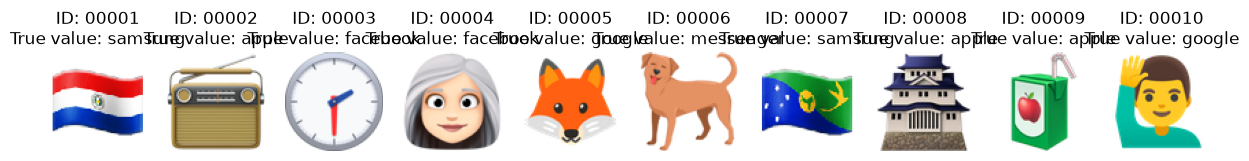

In [118]:
show_img(selected_imgs,selected_titles, array_of_array=True, gray=True, length=15)


## STEP 4 : Train a model on the training dataset

In [119]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)

Using device: mps


### Prepare the data for PyTorch

Labels are strings (`"apple"`, `"samsung"`, ...) but PyTorch needs integer class indices,
so we encode them with a `LabelEncoder` and keep it around to decode predictions back to
strings later. We also carve out a validation split from the training data, since the
real test set has no labels we can check ourselves against.

In [120]:
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train["Label"])
num_classes = len(label_encoder.classes_)
print("Classes:", list(label_encoder.classes_))

X_tr, X_val, meta_tr, meta_val, y_tr, y_val, ids_tr, ids_val = train_test_split(
    X_train, meta_train, y_train_encoded, X_train_ids,
    test_size=0.2, random_state=42, stratify=y_train_encoded,
)
print("Train:", X_tr.shape, "Val:", X_val.shape)

Classes: ['apple', 'facebook', 'google', 'messenger', 'mozilla', 'samsung', 'whatsapp']
Train: (7903, 72, 72, 4) Val: (1976, 72, 72, 4)


In [121]:
class EmojiDataset(Dataset):
    """Wraps (N, H, W, C) uint8 images + (N, 9) file metadata + integer labels as a PyTorch Dataset.

    Images are converted to float tensors in [0, 1] and moved to PyTorch's
    expected (C, H, W) channel layout (C = 4: RGB + alpha).
    """

    def __init__(self, images, meta, labels):
        images = images.astype(np.float32) / 255.0
        self.images = torch.from_numpy(images).permute(0, 3, 1, 2)
        self.meta = torch.from_numpy(meta).float()
        self.labels = torch.from_numpy(labels).long()

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.meta[idx], self.labels[idx]


train_dataset = EmojiDataset(X_tr, meta_tr, y_tr)
val_dataset = EmojiDataset(X_val, meta_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

### Define the CNN

Four convolution blocks, each made of two 3x3 conv layers followed by max pooling. Channels
grow 32 -> 64 -> 128 -> 256 while the image shrinks 72 -> 36 -> 18 -> 9 -> 4.

**Inputs: RGB + alpha + file metadata.** The biggest improvement in this project came from
preprocessing, not from the model (validation accuracy 92.5% -> 95.3%, same architecture,
same training, same split). The original loader did `convert("RGB").resize((72, 72))`, which
throws away two things that identify the vendor:

- **The original image size.** Each vendor exports at its own resolution: `facebook` is
  240x240 (93% of its images), `whatsapp` 160x160 (90%), `apple`/`google`/`samsung` 72x72,
  `messenger`/`mozilla` 240x240. Size alone separates `facebook` from `whatsapp` 96.5% of the
  time, but after resizing everything to 72x72 the CNN could only rely on drawing style. We
  now record the original size and PNG mode (RGBA / palette / grayscale...) as a 9-value
  one-hot vector, concatenated to the 256 image features right before the final layer.
- **The alpha channel.** Every emoji is drawn on a transparent background. Converting to RGB
  silently drops the transparency and keeps whatever color values are stored under the
  transparent pixels (mostly black for `google`/`mozilla`, other colors for `samsung` or
  `facebook`). These hidden values differ by vendor, so we keep them, and add the alpha
  channel as a 4th input channel so the network also sees the true shape of the emoji.

Ablation (one seed each, 30 epochs, same split):

| Input | Val. accuracy | facebook<->whatsapp errors |
|---|---|---|
| RGB only (original loader) | 92.5% | 38 |
| Composited on white + alpha | 90.8% | 26 |
| Raw RGB + alpha | 93.9% | 23 |
| Raw RGB + metadata | 94.6% | 9 |
| **Raw RGB + alpha + metadata (used)** | **95.3%** | **4** |

Compositing on white *hurts*: it erases the hidden colors under transparent pixels. This also
explains why our earlier "background normalization to white" experiment failed (below).

*AI usage: this preprocessing issue was found with the help of an AI assistant (Claude), which
inspected the raw files (sizes, modes, alpha channel) and ran the ablation above.*

The first version (two conv layers + a big fully connected layer) overfit quickly: train
accuracy reached ~99% while validation accuracy plateaued at ~86% and validation loss
started rising after epoch 7. To regularize and stabilize training:

- **BatchNorm** after every conv: normalizes activations, allows a higher learning rate.
- **Dropout2d** after every block: randomly drops whole feature maps during training.
- **Global average pooling** instead of flattening into a big linear layer: the old
  `fc1` alone had 1.3M parameters (most of the model), which made memorizing easy.
- **Dropout** before the final classifier.

**Tried and intentionally not kept: a 5th conv block (256 -> 512 channels, ~4.7M params
instead of ~1.6M).** We hit a ~92.6% ceiling with the 4-block model (RGB-only inputs) that
augmentation, TTA, and hyperparameter tuning couldn't meaningfully move, so we tested whether
more capacity could push past it. It didn't: validation accuracy dropped slightly to 91.9%,
and the train/validation gap widened even after increasing dropout to compensate. In
hindsight the ceiling came from the inputs (see above), not from the model's capacity.

**Tried and intentionally not kept: replacing global average pooling with a
self-attention layer.** We hypothesized that averaging away spatial position in the
final pooling step was discarding real signal (margins/proportions on the canvas),
since we'd already found this task unusually sensitive to spatial perturbation. We
replaced `AdaptiveAvgPool2d` with `nn.MultiheadAttention` over the 16 final spatial
positions plus a learned positional embedding. It performed worse (90.0% vs ~92.6%),
with a similar overfitting gap to the deeper model. Attention has a weaker built-in
inductive bias than convolution/pooling and typically needs more data to learn well from
scratch — with ~7,900 training images, it likely didn't have enough to outlearn the
simpler, more constrained pooling approach.

**Tried and intentionally not kept: background normalization.** Across every RGB-only
architecture, the same two class pairs were the most confused: `facebook`<->`whatsapp` and
`apple`<->`google`. We tried normalizing every image's background to white before training.
It didn't reduce that confusion and hurt overall accuracy (90.9% vs ~92.6%). We now know
why: the "background" was not a drawing choice but the hidden colors under transparent
pixels, which are themselves a vendor fingerprint, and `facebook`<->`whatsapp` confusion was
caused by the resize erasing their different native resolutions.

Note: no data augmentation (flips, shifts, zooms). We tested it and it *hurt* validation
accuracy badly (~0.94 -> ~0.75): the task is recognizing each vendor's drawing *style*
(size on the canvas, margins, lighting direction), which those transforms destroy.

In [122]:
def conv_block(in_channels, out_channels, dropout):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
        nn.Dropout2d(dropout),
    )


class EmojiCNN(nn.Module):
    def __init__(self, num_classes, num_meta, in_channels=4):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(in_channels, 32, dropout=0.1),
            conv_block(32, 64, dropout=0.1),
            conv_block(64, 128, dropout=0.2),
            conv_block(128, 256, dropout=0.2),
        )
        self.pool = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(256 + num_meta, num_classes),
        )

    def forward(self, x, meta):
        # 256 image features + 9 file-metadata values, concatenated before the final layer
        features = torch.cat([self.pool(self.features(x)), meta], dim=1)
        return self.classifier(features)


num_meta = meta_train.shape[1]
print(EmojiCNN(num_classes, num_meta))

EmojiCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(4, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout2d(p=0.1, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05

### Train the model

Standard PyTorch training loop: for each batch, run a forward pass, compute the loss,
backpropagate, and update the weights. After each epoch, we check accuracy on the
validation set (data the model did not train on) to see if it's actually learning.

Training changes compared to the first version:

- **AdamW with weight decay**: penalizes large weights (L2-style regularization).
- **OneCycle learning rate schedule**: warms the learning rate up, then anneals it down,
  which converges faster and to a better minimum than a fixed learning rate.
- **Label smoothing**: the model is trained towards 0.9 confidence instead of 1.0, which
  discourages overconfident predictions.
- **Keep the best epoch**: we save the weights from the epoch with the highest validation
  accuracy and restore them at the end, instead of keeping whatever the last epoch gave.
- **Tuned learning rate and weight decay**: we ran a systematic sequential search
  (sweep `max_lr` with `weight_decay` fixed, then sweep `weight_decay` with the best
  `max_lr` fixed), each configuration trained for the full 30 epochs so results are
  directly comparable to this cell. `max_lr=2e-3, weight_decay=1e-4` beat the original
  guess (`max_lr=3e-3, weight_decay=5e-4`) by about half a point of validation accuracy
  (0.931 vs 0.925), and weight decay showed a clear, monotonic trend: lower values
  consistently did better. Used here.

**Tried and intentionally not kept: class weighting.** The classes are imbalanced
(`mozilla` has ~400 training images vs. ~1,900 for `apple`), and the earlier confusion
matrix showed `mozilla` had by far the worst per-class accuracy. We tried weighting the
loss inversely to class frequency, which fixed that specific weakness well (`mozilla`
recall went from ~58% to ~89%), but it cost ~1 point of overall validation accuracy by
making the model less confident on the majority classes. Since the competition is graded
on plain accuracy, we optimize for that directly here and leave class weighting out —
but it remains a concrete, defensible option if per-class fairness mattered more than the
single aggregate number.


In [123]:
import copy


def run_epoch(model, loader, criterion, optimizer=None, scheduler=None):
    """Runs one pass over `loader`. If `optimizer` is given, trains; otherwise, evaluates."""
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(is_training):
        for images, meta, labels in loader:
            images, meta, labels = images.to(device), meta.to(device), labels.to(device)

            outputs = model(images, meta)
            loss = criterion(outputs, labels)

            if is_training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                if scheduler is not None:
                    scheduler.step()

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += images.size(0)

    return total_loss / total, correct / total


def train_model(train_loader, val_loader=None, num_epochs=30):
    """Trains a fresh EmojiCNN.

    With a `val_loader`, reports validation metrics each epoch and restores the best epoch.
    Without one, keeps the weights of the last epoch.
    """
    model = EmojiCNN(num_classes, num_meta).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=2e-3, total_steps=num_epochs * len(train_loader)
    )

    best_val_acc, best_state = 0.0, None
    for epoch in range(1, num_epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer, scheduler)
        log = f"Epoch {epoch:2d}/{num_epochs} | train loss {train_loss:.4f} acc {train_acc:.3f}"
        if val_loader is not None:
            val_loss, val_acc = run_epoch(model, val_loader, criterion)
            if val_acc > best_val_acc:
                best_val_acc, best_state = val_acc, copy.deepcopy(model.state_dict())
            log += f" | val loss {val_loss:.4f} acc {val_acc:.3f}"
        print(log)

    if val_loader is not None:
        model.load_state_dict(best_state)
        print(f"Restored best model (val acc {best_val_acc:.3f})")
    return model


model = train_model(train_loader, val_loader)

Epoch  1/30 | train loss 1.6207 acc 0.403 | val loss 1.3321 acc 0.524
Epoch  2/30 | train loss 1.3243 acc 0.546 | val loss 1.1640 acc 0.657
Epoch  3/30 | train loss 1.1360 acc 0.677 | val loss 0.9844 acc 0.766
Epoch  4/30 | train loss 1.0301 acc 0.734 | val loss 0.9300 acc 0.792
Epoch  5/30 | train loss 0.9505 acc 0.784 | val loss 0.9687 acc 0.750
Epoch  6/30 | train loss 0.8985 acc 0.806 | val loss 0.8420 acc 0.841
Epoch  7/30 | train loss 0.8564 acc 0.831 | val loss 0.8228 acc 0.856
Epoch  8/30 | train loss 0.8170 acc 0.851 | val loss 0.7702 acc 0.870
Epoch  9/30 | train loss 0.7982 acc 0.857 | val loss 0.7522 acc 0.881
Epoch 10/30 | train loss 0.7621 acc 0.874 | val loss 0.7359 acc 0.880
Epoch 11/30 | train loss 0.7448 acc 0.880 | val loss 0.7487 acc 0.892
Epoch 12/30 | train loss 0.7242 acc 0.894 | val loss 0.7318 acc 0.881
Epoch 13/30 | train loss 0.7023 acc 0.902 | val loss 0.6938 acc 0.906
Epoch 14/30 | train loss 0.6865 acc 0.912 | val loss 0.6782 acc 0.916
Epoch 15/30 | train 

### Checking results: confusion matrix on the validation set

The training loop above already reports validation accuracy each epoch (data the model
never trained on) — that's the honest local estimate of performance, since the real
Kaggle test set has no labels available to us locally.

A confusion matrix goes one step further: it shows *which* classes get mixed up with
which. Row = true label, column = predicted label. The diagonal is correct predictions;
anything off-diagonal is a specific type of mistake (e.g. `facebook` predicted as
`messenger`, which makes sense since Meta owns both and their emoji art styles are close).

Final validation accuracy: 0.951


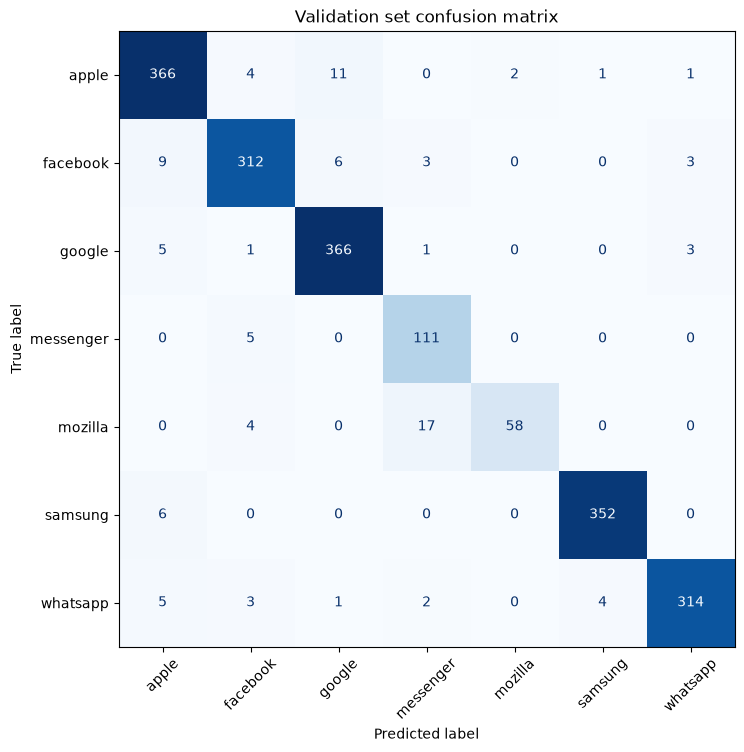

In [124]:
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

model.eval()
val_preds, val_true = [], []
with torch.no_grad():
    for images, meta, labels in val_loader:
        outputs = model(images.to(device), meta.to(device))
        val_preds.append(outputs.argmax(1).cpu().numpy())
        val_true.append(labels.numpy())

val_preds = np.concatenate(val_preds)
val_true = np.concatenate(val_true)

final_val_accuracy = accuracy_score(val_true, val_preds)
print(f"Final validation accuracy: {final_val_accuracy:.3f}")

cm = confusion_matrix(val_true, val_preds)
disp = ConfusionMatrixDisplay(cm, display_labels=label_encoder.classes_)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Validation set confusion matrix")
plt.show()

### What is actually confusing the model: looking at the real misclassified images

With RGB-only inputs, `facebook`<->`whatsapp` and `apple`<->`google` were the two most
confused pairs, consistently across every architecture we tried (plain CNN, deeper CNN,
attention). Below, we pull real examples the current model still gets wrong for both pairs.
Images are displayed with their real transparency (RGB + alpha).

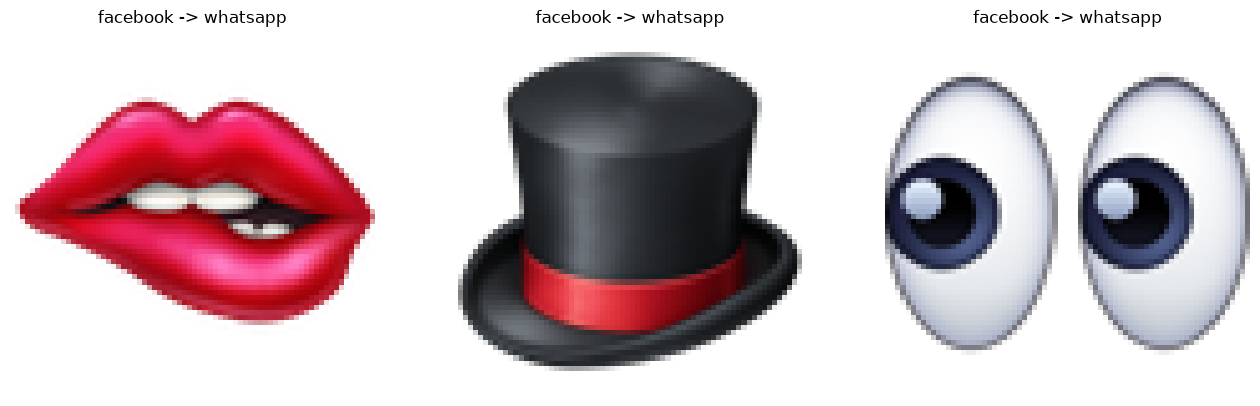

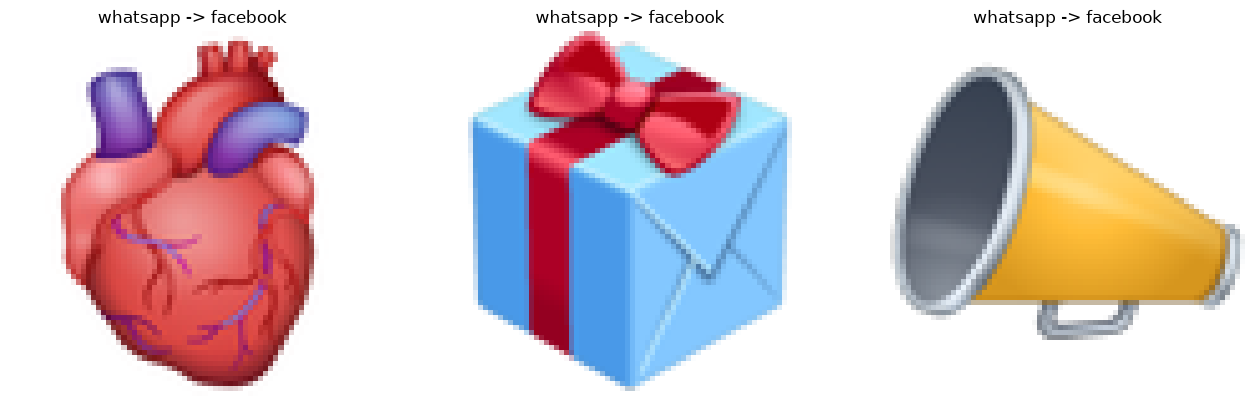

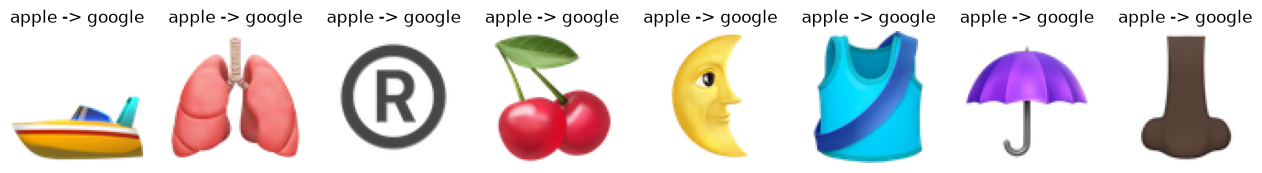

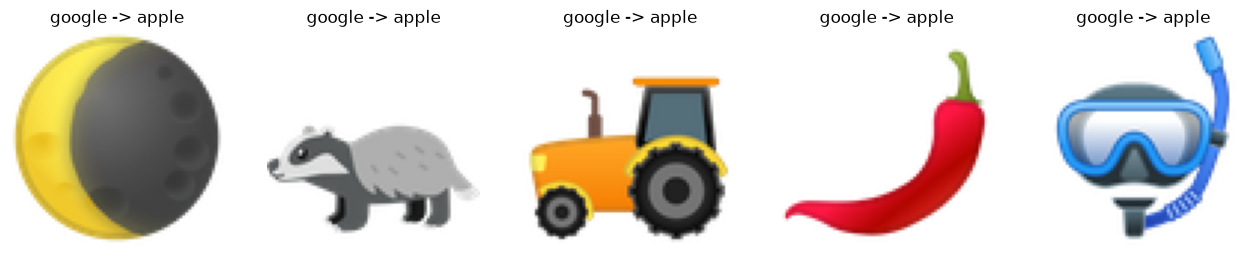

In [125]:
def show_misclassified(true_cls, pred_cls, n=8):
    true_idx = list(label_encoder.classes_).index(true_cls)
    pred_idx = list(label_encoder.classes_).index(pred_cls)
    mask = (val_true == true_idx) & (val_preds == pred_idx)
    matched = [i for i in range(len(mask)) if mask[i]][:n]

    imgs = [X_val[i] for i in matched]
    titles = [f"{true_cls} -> {pred_cls}" for _ in matched]
    if imgs:
        show_img(imgs, titles, array_of_array=True, length=16)
    else:
        print(f"No {true_cls} -> {pred_cls} misclassifications found in this run.")


show_misclassified("facebook", "whatsapp")
show_misclassified("whatsapp", "facebook")
show_misclassified("apple", "google")
show_misclassified("google", "apple")

**Earlier finding, corrected.** With RGB-only inputs, almost every misclassified image in
these two pairs was an *object, food, or animal* emoji shown on a black square, and we
concluded that these four vendors share a "photorealistic black-background" style. That
conclusion was wrong: the black square was created by our own loader. The emoji actually sit
on a transparent background, and `convert("RGB")` displayed the (mostly black) colors stored
under the transparent pixels.

The real causes, found by inspecting the raw files:

- `facebook`<->`whatsapp`: their native resolutions differ (240x240 vs 160x160) and the resize
  to 72x72 erased that. Adding the original size as an input brings this confusion from ~38
  errors to ~4 on the validation set.
- `apple`<->`google`: both are 72x72 RGBA files, so no file property separates them. This is
  the remaining genuinely visual confusion (~15 errors), together with `mozilla`->`messenger`
  (both 240x240).

### Test-time augmentation (TTA): tried, not kept

We also tested test-time augmentation — running each validation image through the model
multiple times (original + mild flip/rotation) and averaging the predictions. Unlike
training-time augmentation, this never touches what the model learned, only how
predictions are produced.

Result: it hurt validation accuracy here too (0.923 -> 0.913), consistent with the
earlier finding that this task is unusually sensitive to any spatial perturbation, even
when only applied at inference time and averaged with the original. Not used for the
final predictions. The full implementation and result are preserved in git history.

## STEP 5 : Make predictions (random ones)

In [126]:
def predict_with_my_amazing_model(model, X_test, meta_test):
    model.eval()
    images = torch.from_numpy(X_test.astype(np.float32) / 255.0).permute(0, 3, 1, 2)
    meta = torch.from_numpy(meta_test)

    all_preds = []
    with torch.no_grad():
        for i in range(0, len(images), 64):
            outputs = model(images[i : i + 64].to(device), meta[i : i + 64].to(device))
            all_preds.append(outputs.argmax(1).cpu().numpy())

    predicted_indices = np.concatenate(all_preds)
    return label_encoder.inverse_transform(predicted_indices)

In [127]:
y_test_pred = predict_with_my_amazing_model(model, X_test, meta_test)

In [128]:
y_test_pred

array(['google', 'messenger', 'samsung', ..., 'apple', 'google', 'apple'],
      shape=(9879,), dtype=object)

In [129]:
X_test_ids_sr = pd.Series(X_test_ids, name="Id")
y_test_pred_sr = pd.Series(y_test_pred, name="Label")
submission_df = pd.concat([X_test_ids_sr, y_test_pred_sr], axis=1)

In [130]:
submission_df.head()

,Id,Label
0,10001,google
1,10002,messenger
2,10003,samsung
3,10004,whatsapp
4,10005,samsung


In [131]:
submission_df.to_csv("submission.csv", index=False)